# Predicting Live Hen Market Prices in Rwanda
**Mission:** Help Rwandan youth and small holder farmers succeed in poultry farming by guiding farm setup, flock care, vet access and profit tracking.

**use case:** predict the retail price(RWF) of a live hen in a given Rwandan market and month. Poultry farmers use this to decide where and when to sell their birds and to estimate income before going to market.

**Data used:** WFP(World Food Program) Food prices for Rwanda(Humanitarian Data Exchange) - real monthly msrket price surveys.

**1. Imports**

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

**2. Load the raw data**

In [21]:
raw = pd.read_csv('wfp_food_prices_rwa.csv')

#remove the second row tags like '#date' if it is present
raw = raw[~raw["date"].astype(str).str.startswith('#')].copy()
for col in ['price', 'latitude', 'longitude']:
    raw[col] = pd.to_numeric(raw[col])
print(raw.shape)
raw.head()

(157793, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


## Building the modeling table

The raw file has one row per (market, month, commodity). We keep only **retail live hen prices** as target, the add the price of other commodities **in the same market and month** as features:
- **Eggs** - the other main poultry product
- **Maize and soybeans** - the main ingredients in poultry feed (a cost signal)
- **Dry beans and beef** - general food price level in that market

**3. Building the table**

In [22]:
retail = raw[raw["pricetype"] == "Retail"]
hen = retail[retail["commodity"] == "Livestock (hen)"][
    ["date", "admin1", "admin2", "market", "latitude", "longitude", "price"]
].rename(columns={"admin1": "province", "admin2": "district", "price": "hen_price"})

other_commodities = {
    "Eggs": "egg_price",
    "Maize": "maize_price",
    "Soybeans": "soybean_price",
    "Beans (dry)": "beans_price",
    "Meat (beef)": "beef_price",
}

for commodity, new_col in other_commodities.items():
    prices = (retail[retail["commodity"] == commodity]
              .groupby(["market", "date"])["price"].mean()
              .rename(new_col).reset_index())
    hen = hen.merge(prices, on=["market", "date"], how="left")

hen["date"] = pd.to_datetime(hen["date"])
hen["year"] = hen["date"].dt.year
hen["month"] = hen["date"].dt.month

print(hen.shape)
hen.head()

(1949, 14)


,date,province,district,market,latitude,longitude,hen_price,egg_price,maize_price,soybean_price,beans_price,beef_price,year,month
0,2012-01-15,Eastern Province,Bugesera,Nyamata,-2.21,30.24,2425.00,88.75,225.00,350.00,212.50,1625.00,2012,1
1,2012-01-15,Eastern Province,Bugesera,Ruhuha,-2.15,30.09,2500.00,78.75,250.00,400.00,200.00,1500.00,2012,1
2,2012-01-15,Eastern Province,Gatsibo,Kimironko,-1.75,30.34,3166.88,78.88,300.00,454.25,301.75,2124.75,2012,1
3,2012-01-15,Eastern Province,Gatsibo,Rwagitima,-1.80,30.42,4366.40,79.40,171.50,328.00,224.60,1533.33,2012,1
4,2012-01-15,Eastern Province,Kayonza,Kabarondo,-2.02,30.55,4450.25,93.75,281.25,383.25,197.50,1600.00,2012,1


**4. Handling missing values and outliers**

In [23]:
print("Missing values per column:\n", hen.isna().sum())

df = hen.dropna().copy()
print("\nAfter dropping missing rows:", df.shape)

# A few hen prices are 2-3x the normal range (likely data-entry errors)
print("\nHighest hen prices:\n", df["hen_price"].sort_values().tail(6).values)
df = df[df["hen_price"] <= 8000]
print("After removing extreme outliers:", df.shape)

df["hen_price"].describe()

Missing values per column:
 date               0
province           0
district           0
market             0
latitude           0
longitude          0
hen_price          0
egg_price         28
maize_price      136
soybean_price    149
beans_price        0
beef_price        54
year               0
month              0
dtype: int64

After dropping missing rows: (1643, 14)

Highest hen prices:
 [ 6750.    6833.33  8958.25  9966.8  11625.75 13399.8 ]
After removing extreme outliers: (1639, 14)


count    1639.000000
mean     3895.236693
std       694.142965
min      2000.000000
25%      3500.000000
50%      3950.000000
75%      4333.000000
max      6833.330000
Name: hen_price, dtype: float64

**5. Visual 1: Target Distribution and price per province**

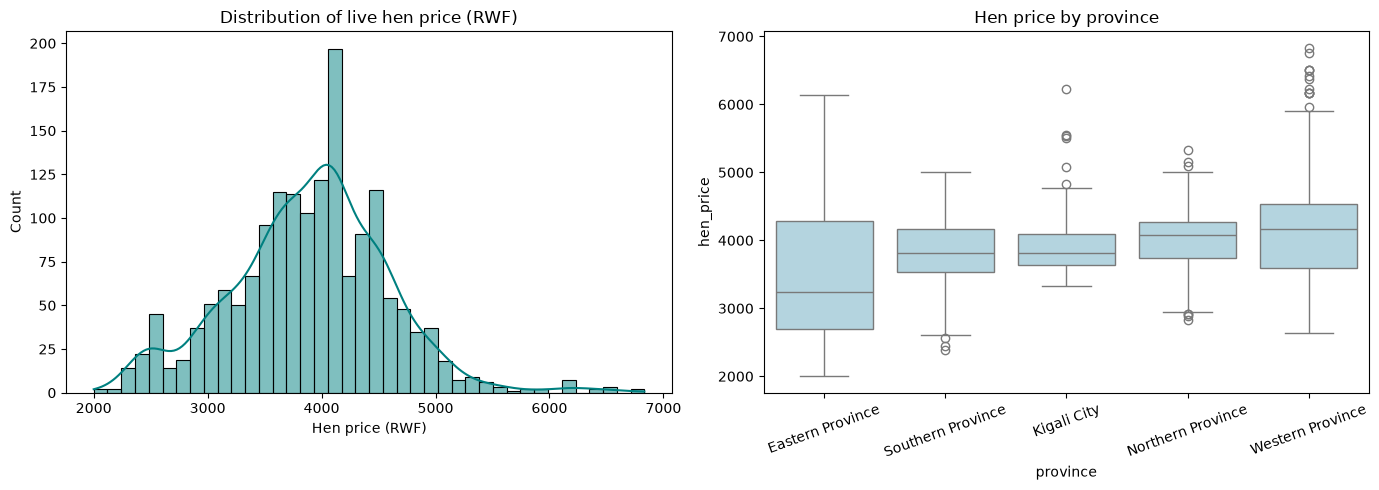

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["hen_price"], bins=40, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribution of live hen price (RWF)")
axes[0].set_xlabel("Hen price (RWF)")

order = df.groupby("province")["hen_price"].mean().sort_values().index
sns.boxplot(data=df, x="province", y="hen_price", order=order, ax=axes[1], color="lightblue")
axes[1].set_title("Hen price by province")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**What it shows:** Hen prices are roughly bell-shaped around 3,900 RWF (most between 3,500 and 4,300) with very little skew, so no log transform of the target is needed. Prices differ clearly by province: Eastern Province is cheapest (~3,490 RWF on average) and Western Province most expensive (~4,190 RWF).

**Decision:** Removing the 4 extreme prices (>8,000 RWF) was justified since they sit far outside this distribution. Because location clearly matters, we keep **province and district** as categorical features and encode them for the models.

**6. Visual 2: Correlation heatmap**

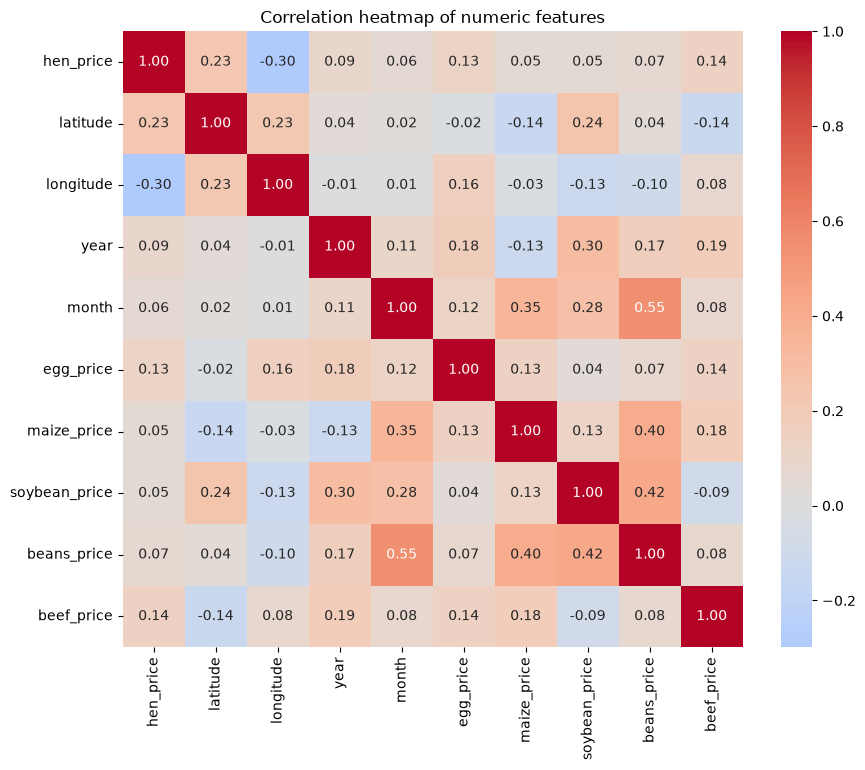

In [25]:
num_cols = ["hen_price", "latitude", "longitude", "year", "month",
            "egg_price", "maize_price", "soybean_price", "beans_price", "beef_price"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features")
plt.show()

**What it shows:** No single feature is strongly correlated with hen price. The strongest is **longitude (-0.30)** - prices fall as you move east - followed by latitude (0.23), beef price (0.14) and egg price (0.13). Feed prices (maize 0.05, soybean 0.05) have weak direct links. Feature-to-feature correlations are moderate at most (the highest is 0.55 between month and beans price, a seasonal harvest effect), so there is no serious multicollinearity.

**Decision:** Because relationships are weak and likely non-linear (location * season * local food prices), we expect **tree-based models to beat linear regression**. We keep all these features since none is redundant, and use **longitude** for the single-feature scatter plots later.

## Feature engineering

**Dropped columns and why:**
- `market_id`, `commodity_id`, `category`, `commodity`, `unit`, `currency`, `pricetype`, `priceflag` - identifiers or constant after filtering (all rows are retail, RWF, live hen)
- `usdprice` - the same price in another currency; using it would leak the target
- `market` - 60 values, already captured by district + latitude/longitude
- `date` - replaced by `year` and `month`

**Final features (11):** province, district (categorical) + latitude, longitude, year, month, egg_price, maize_price, soybean_price, beans_price, beef_price (numeric).

**Most important for the target:** location (longitude, latitude, province, district), then local food price levels (beef and egg prices).

## Preparing the data for modelling

- **Categorical -> numeric:** `province` and `district` are one-hot encoded.
- **Split:** 80% train / 20% test (`random_state=42` so results are reproducible).
- **Standardization:** numeric features are scaled with `StandardScaler`, **fitted on the training set only** and then applied to the test set, so no test information leaks into training.

Both steps live in one `ColumnTransformer`, which we save together with the best model so the API can apply exactly the same preprocessing.

**7. Hot Encoding and splitting the data for train and test**

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

cat_features = ["province", "district"]
num_features = ["latitude", "longitude", "year", "month", "egg_price",
                "maize_price", "soybean_price", "beans_price", "beef_price"]
features = cat_features + num_features
target = "hen_price"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
    ("num", StandardScaler(), num_features),
])

# Fit on TRAIN only, then transform both
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Train:", X_train_p.shape, " Test:", X_test_p.shape)

Train: (1311, 41)  Test: (328, 41)


## Model 1: Linear regression by gradient descent (SGDRegressor)

We train with `partial_fit` in a loop (one pass over the data per epoch) and record train and test MSE after every epoch. We tune three hyperparameters:
- **Learning rate (`eta0`)**: 0.0001, 0.001, 0.01
- **Regularization strength (`alpha`)**: 0.0001, 0.001, 0.01, 0.1
- **Number of epochs**: 50, 100, 200

**8. SDG Tuning**

In [27]:
def train_sgd(eta0, alpha, epochs):
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, random_state=42)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.partial_fit(X_train_p, y_train)
        train_losses.append(mean_squared_error(y_train, model.predict(X_train_p)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_p)))
    return model, train_losses, test_losses

results = []
for eta0 in [0.0001, 0.001, 0.01]:
    for alpha in [0.0001, 0.001, 0.01, 0.1]:
        for epochs in [50, 100, 200]:
            _, tr, te = train_sgd(eta0, alpha, epochs)
            results.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                            "train_mse": round(tr[-1]), "test_mse": round(te[-1])})

tuning = pd.DataFrame(results).sort_values("test_mse")
tuning.head(10)

,eta0,alpha,epochs,train_mse,test_mse
14,0.001,0.0001,200,200416,197283
17,0.001,0.0010,200,201136,200511
13,0.001,0.0001,100,202971,205252
16,0.001,0.0010,100,203599,207656
25,0.010,0.0001,100,213253,216776
24,0.010,0.0001,50,213972,217014
26,0.010,0.0001,200,213191,217102
29,0.010,0.0010,200,213818,220135
28,0.010,0.0010,100,213980,220278
27,0.010,0.0010,50,214706,220952


In [30]:
from IPython.display import Markdown

# The rows behind the tuning notes: each table changes one hyperparameter
effect_of_learning_rate = tuning[(tuning.alpha == 0.0001) & (tuning.epochs == 100)].sort_values("eta0")
effect_of_regularization = tuning[(tuning.eta0 == 0.001) & (tuning.epochs == 200)].sort_values("alpha")
effect_of_epochs = tuning[(tuning.eta0 == 0.001) & (tuning.alpha == 0.0001)].sort_values("epochs")

display(Markdown("**Learning rate** (alpha = 0.0001, 100 epochs)"))
display(effect_of_learning_rate)
display(Markdown("**Regularization** (eta0 = 0.001, 200 epochs)"))
display(effect_of_regularization)
display(Markdown("**Epochs** (eta0 = 0.001, alpha = 0.0001)"))
display(effect_of_epochs)

**Learning rate** (alpha = 0.0001, 100 epochs)

,eta0,alpha,epochs,train_mse,test_mse
1,0.0001,0.0001,100,269008,317606
13,0.0010,0.0001,100,202971,205252
25,0.0100,0.0001,100,213253,216776


**Regularization** (eta0 = 0.001, 200 epochs)

,eta0,alpha,epochs,train_mse,test_mse
14,0.001,0.0001,200,200416,197283
17,0.001,0.0010,200,201136,200511
20,0.001,0.0100,200,212913,230373
23,0.001,0.1000,200,282132,333538


**Epochs** (eta0 = 0.001, alpha = 0.0001)

,eta0,alpha,epochs,train_mse,test_mse
12,0.001,0.0001,50,209093,223556
13,0.001,0.0001,100,202971,205252
14,0.001,0.0001,200,200416,197283


**Tuning results:**
- **Learning rate:** 0.001 worked best. At 0.0001 the model learns too slowly (test MSE ~318,000 after 100 epochs); at 0.01 the steps are too large and it settles at a worse point (~217,000).
- **Regularization:** smaller is better here (0.0001). Strong regularization (0.1) pushes the weights too close to zero and the model underfits (test MSE ~334,000).
- **Epochs:** more epochs helped - 50 -> 100 -> 200 lowered test MSE from ~224,000 to ~197,000, with no sign of overfitting.

**Best SGD settings:** eta0 = 0.001, alpha = 0.0001, 200 epochs.

**9. Final SDG and loss curve**

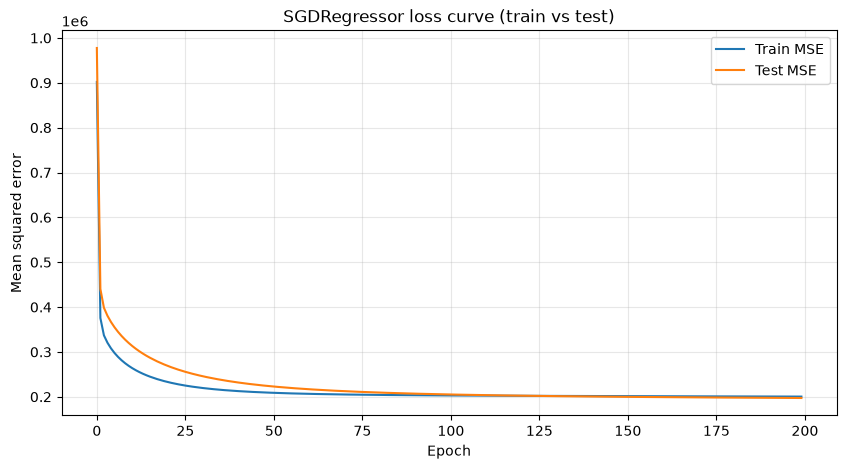

Final train MSE: 200,416
Final test MSE:  197,283


In [ ]:
sgd_model, sgd_train_losses, sgd_test_losses = train_sgd(eta0=0.001, alpha=0.0001, epochs=200)

plt.figure(figsize=(10, 5))
plt.plot(sgd_train_losses, label="Train MSE")
plt.plot(sgd_test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("SGDRegressor loss curve (train vs test)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Final train MSE: {sgd_train_losses[-1]:,.0f}")
print(f"Final test MSE:  {sgd_test_losses[-1]:,.0f}")

**Loss curve:** Both losses fall sharply in the first 10 epochs, then flatten - the model has converged. Train and test MSE stay very close the whole way, so SGD is **not overfitting**; its limit is that it can only draw a straight-line (linear) relationship, which doesn't capture how location, season and food prices interact.

**10. The other 3 models**

In [ ]:
models = {
    "Linear Regression (closed form)": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

fitted = {}
comparison = [{
    "Model": "Linear Regression (SGD)",
    "Train MSE": round(sgd_train_losses[-1]),
    "Test MSE": round(sgd_test_losses[-1]),
}]

for name, model in models.items():
    model.fit(X_train_p, y_train)          # train on the already-scaled/encoded data
    fitted[name] = model
    comparison.append({
        "Model": name,
        "Train MSE": round(mean_squared_error(y_train, model.predict(X_train_p))),
        "Test MSE": round(mean_squared_error(y_test, model.predict(X_test_p))),
    })

**11. Comparison Table**

In [ ]:
comparison_df = pd.DataFrame(comparison).sort_values("Test MSE").reset_index(drop=True)
comparison_df

,Model,Train MSE,Test MSE
0,Random Forest,13971,108982
1,Decision Tree,0,171765
2,Linear Regression (closed form),195577,186904
3,Linear Regression (SGD),200416,197283


## Best model: Random Forest (lowest test MSE ~= 108,982)

**Criterion:** the best model is the one with the **lowest test MSE**, because test data was never seen during training and shows how well each model predicts new market prices.

**How the dataset affected each model:**
- **Both linear models** (~187,000-197,000) perform similarly and don't overfit (train ~= test), but they are limited because no single feature has a strong linear link to hen price (max correlation 0.30). SGD lands slightly above the closed-form solution because gradient descent approaches, but doesn't exactly reach, the optimal weights.
- **Decision Tree** memorises the training data (train MSE = 0) but generalises poorly (test ~171,765) - classic **overfitting** on a small, noisy dataset.
- **Random Forest** averages 300 trees, which keeps the tree's ability to capture non-linear interactions (e.g. Eastern Province + certain months) while cancelling out individual trees' overfitting. It cuts test error by ~42% compared to linear regression.

A test MSE of ~109,000 means a typical error (RMSE) of about **330 RWF** on prices averaging ~3,900 RWF (about 8.5%).

## Scatter plots: most correlated feature vs target

The feature most correlated with hen price is **longitude** (r = -0.30). We plot it against hen price, then draw a **one-feature linear regression line** fitted on longitude only (used for this plot only).

**12. Scatter Plot Before**

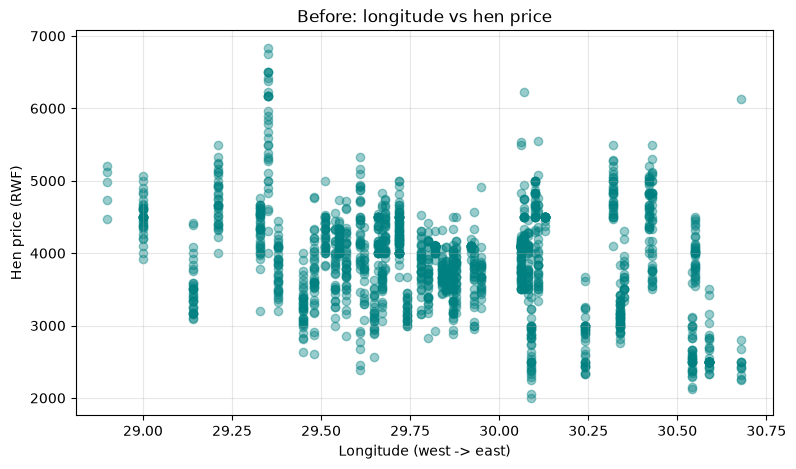

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(df["longitude"], df["hen_price"], alpha=0.4, color="teal")
plt.xlabel("Longitude (west -> east)")
plt.ylabel("Hen price (RWF)")
plt.title("Before: longitude vs hen price")
plt.grid(alpha=0.3)
plt.show()

**What it shows:** Hen price plotted against longitude, the feature most correlated with price (r = -0.30). There is a weak downward trend (hens are cheaper further east), but the points are widely spread, so longitude alone cannot predict the price well.

**Decision:** This confirmed we need a multivariate model that combines location with time and local prices, rather than a single-feature model.

**13. Scatter Plot after**

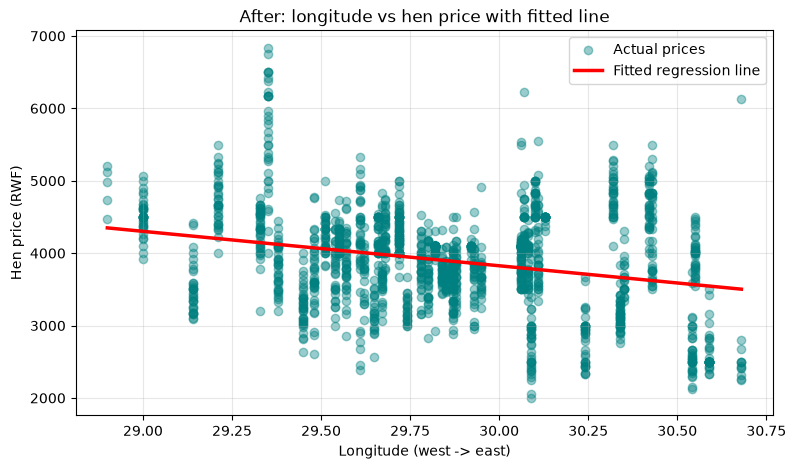

Slope: -475 RWF per degree of longitude


In [ ]:
line_model = LinearRegression()
line_model.fit(X_train[["longitude"]], y_train)

x_line = np.linspace(df["longitude"].min(), df["longitude"].max(), 100).reshape(-1, 1)
y_line = line_model.predict(pd.DataFrame(x_line, columns=["longitude"]))

plt.figure(figsize=(9, 5))
plt.scatter(df["longitude"], df["hen_price"], alpha=0.4, color="teal", label="Actual prices")
plt.plot(x_line, y_line, color="red", linewidth=2.5, label="Fitted regression line")
plt.xlabel("Longitude (west -> east)")
plt.ylabel("Hen price (RWF)")
plt.title("After: longitude vs hen price with fitted line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Slope: {line_model.coef_[0]:,.0f} RWF per degree of longitude")

**What it shows:** The line slopes downward - markets further east (Eastern Province) sell hens for less, about 475 RWF cheaper per degree of longitude. But the points are widely scattered around the line, which confirms that one feature alone explains little of the price. This is why the multivariate models, and especially Random Forest, perform better.

**14. Saving the best model**

In [ ]:
import joblib

best_model = fitted["Random Forest"]

bundle = {
    "preprocessor": preprocessor,            # encoding + scaling, fitted on train only
    "model": best_model,                     # the Random Forest
    "cat_features": cat_features,
    "num_features": num_features,
    "target": target,
    "training_data": df[features + [target]].reset_index(drop=True),  # used by /retrain
}

joblib.dump(bundle, "../API/best_model.pkl", compress=3)
print("Saved best model (Random Forest) to API/best_model.pkl")

Saved best model (Random Forest) to API/best_model.pkl


**15. Prediction function**

In [ ]:
def predict_hen_price(input_row, model_path="../API/best_model.pkl"):
    """Load the saved model and predict hen price for one row of input data."""
    saved = joblib.load(model_path)
    features = saved["cat_features"] + saved["num_features"]
    row = pd.DataFrame([input_row])[features] if isinstance(input_row, dict) else input_row[features]
    row_processed = saved["preprocessor"].transform(row)
    return float(saved["model"].predict(row_processed)[0])

# Predict for one row of the TEST set
one_row = X_test.iloc[[0]]
print(one_row.to_dict("records")[0])
print(f"\nActual price:    {y_test.iloc[0]:,.0f} RWF")
print(f"Predicted price: {predict_hen_price(one_row):,.0f} RWF")

{'province': 'Northern Province', 'district': 'Gicumbi', 'latitude': -1.53, 'longitude': 30.08, 'year': 2014, 'month': 2, 'egg_price': 100.0, 'maize_price': 208.75, 'soybean_price': 443.75, 'beans_price': 331.0, 'beef_price': 1800.0}

Actual price:    4,046 RWF
Predicted price: 3,923 RWF


## Interpretation

- **Best model:** Random Forest, test MSE ≈ 108,982 (RMSE ~= 330 RWF), saved with its preprocessing to `API/best_model.pkl`.
- **One-row prediction:** the saved model predicted ~3,923 RWF for a hen that actually sold for 4,046 RWF — an error of about 3%.
- The `predict_hen_price` function accepts either a test-set row or a dictionary of inputs, and is reused in the API.

## Limitations and how the model stays current

The WFP dataset only records live hen and egg prices for **2012–2015**. Since then, prices in Rwanda have risen sharply (COVID-19, inflation, feed costs). In the same WFP data, median maize rose from ~224 to ~550 RWF, dry beans from ~392 to ~850 RWF, and beef from ~1,775 to ~7,000 RWF between 2015 and 2025–26.

Because Random Forest cannot extrapolate beyond the values it was trained on, it will **underpredict** current hen prices. The fix is new data: the API's `/retrain` endpoint accepts a CSV of recent market observations and refits the model on the original data plus the new rows, so predictions catch up with current prices without redeploying.

**Future improvement:** predict hen price *relative to* local food prices (e.g. a hen-to-beef price ratio), which is more stable over time and would scale automatically with inflation.

**16. Sample CSV for testing the /retrain endpoint**

In [ ]:
# Real rows from the dataset, used to demonstrate the /retrain endpoint
sample = df[features + [target]].sample(30, random_state=1)
sample.to_csv("retrain_sample.csv", index=False)
print("Saved retrain_sample.csv with", len(sample), "rows")

Saved retrain_sample.csv with 30 rows
